# Smart Bike Rental Demand Predictor — Training Notebook



**For the existing project, train with `hour.csv`.** The Streamlit application predicts hourly rentals and expects the hourly feature columns. `day.csv` is a daily dataset with a different time granularity and must be treated as a separate daily prediction model.

## What this notebook does
1. Upload `hour.csv` and/or `day.csv`.
2. Inspect and clean the selected dataset.
3. Examine possible outliers without automatically deleting valid high-demand hours.
4. Split data chronologically into 70% train, 15% validation, 15% test.
5. Compare Dummy Regressor, Linear Regression, Random Forest, Extra Trees, and Hist Gradient Boosting.
6. Select the model with the lowest validation RMSE, refit it on train + validation, evaluate on test.
7. Save a `.joblib` model file and download it for the project.

**Important:** Model results will be produced when you run the notebook. Do not claim a specific algorithm is best until you see your own results.

## Step 1 — Install libraries

Run this cell first. Google Colab already includes most libraries, but this ensures the required packages are available.

In [2]:
!pip install pandas numpy sklearn joblib matplotlib

  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


In [3]:

import numpy as np
import pandas as pd
import sklearn

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("All imports successful!")


NumPy: 2.2.6
Pandas: 2.2.3
Scikit-learn: 1.9.1
All imports successful!


## Step 2 — Upload the CSV dataset(s)

Click **Choose Files** and upload `hour.csv`, `day.csv`, or both. If you upload both, the next cell lets you choose which one to train.

For the existing Smart Bike Rental Demand Predictor application, choose **hour**.

In [4]:
from google.colab import files
uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded:
    print(" -", filename)

Saving hour.csv to hour (2).csv

Uploaded files:
 - hour (2).csv


## Step 3 — Choose hourly or daily training

Set `DATASET_TO_TRAIN` to `"hour"` or `"day"`.

- `"hour"`: recommended; creates `bike_demand_model.joblib`, intended for the existing hourly app.
- `"day"`: creates `daily_bike_demand_model.joblib`, a separate daily model. It is **not compatible** with the existing hourly frontend without changing the application features.

In [5]:
DATASET_TO_TRAIN = "hour"  # Change to "day" only if you want a separate daily model

assert DATASET_TO_TRAIN in {"hour", "day"}, "Choose 'hour' or 'day'."

expected_filename = f"{DATASET_TO_TRAIN}.csv"
available_csvs = [name for name in uploaded.keys() if name.lower().endswith(".csv")]

# Match the expected official filename first; if the upload was renamed, use the first CSV.
matches = [name for name in available_csvs if name.lower() == expected_filename]
if matches:
    DATA_FILE = matches[0]
elif len(available_csvs) == 1:
    DATA_FILE = available_csvs[0]
else:
    raise ValueError(
        f"Could not identify {expected_filename}. Uploaded CSVs: {available_csvs}. "
        "Upload the official file name or upload only the CSV you want to use."
    )

print("Training dataset:", DATA_FILE)

Training dataset: hour (2).csv


## Step 4 — Load and inspect the data

The official dataset has 17 columns in `hour.csv` and 16 in `day.csv`. `cnt` is the target (number of rentals).

In [6]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

df = pd.read_csv(io.BytesIO(uploaded[DATA_FILE]))
df.columns = [c.strip().lower() for c in df.columns]

print("Shape:", df.shape)
print("Columns:", list(df.columns))
display(df.head())
display(df.describe(include="all").T)

Shape: (17379, 17)
Columns: ['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
instant,17379.0,NaN,NaN,NaN,8690.0,5017.0295,1.0,4345.5,8690.0,13034.5,17379.0
dteday,17379,731,2012-12-31,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,17379.0,NaN,NaN,NaN,2.50164,1.106918,1.0,2.0,3.0,3.0,4.0
yr,17379.0,NaN,NaN,NaN,0.502561,0.500008,0.0,0.0,1.0,1.0,1.0
mnth,17379.0,NaN,NaN,NaN,6.537775,3.438776,1.0,4.0,7.0,10.0,12.0
hr,17379.0,NaN,NaN,NaN,11.546752,6.914405,0.0,6.0,12.0,18.0,23.0
holiday,17379.0,NaN,NaN,NaN,0.02877,0.167165,0.0,0.0,0.0,0.0,1.0
weekday,17379.0,NaN,NaN,NaN,3.003683,2.005771,0.0,1.0,3.0,5.0,6.0
workingday,17379.0,NaN,NaN,NaN,0.682721,0.465431,0.0,0.0,1.0,1.0,1.0
weathersit,17379.0,NaN,NaN,NaN,1.425283,0.639357,1.0,1.0,1.0,2.0,4.0


## Step 5 — Clean the data and choose features

Cleaning performed here:
- Parse `dteday` as a date.
- Drop rows with an invalid date or missing target `cnt`.
- Remove exact duplicate rows.
- Remove impossible negative target values.
- Sort chronologically before splitting.
- Exclude identifier/date fields from model features where appropriate.
- Exclude `casual` and `registered`, because `casual + registered = cnt` and including them would leak the answer.

**Outlier policy:** This dataset can legitimately have high rental counts during busy hours or seasons. We will *identify and visualize* extreme values, but will not automatically delete them using IQR. Dropping genuine peak demand can make the model worse. The model's tree algorithms are also relatively robust to feature outliers. Numeric imputation/scaling and categorical imputation/encoding are placed in the model pipeline.

In [7]:
required_common = {"dteday", "season", "yr", "mnth", "holiday", "weekday",
                   "workingday", "weathersit", "temp", "atemp", "hum", "windspeed", "cnt"}
missing = required_common - set(df.columns)
if missing:
    raise ValueError(f"Dataset is missing expected columns: {sorted(missing)}")

if DATASET_TO_TRAIN == "hour" and "hr" not in df.columns:
    raise ValueError("hour.csv must include the 'hr' column. Upload the official hourly dataset.")
if DATASET_TO_TRAIN == "day" and "hr" in df.columns:
    print("This file contains an hour column; check that you selected the intended dataset.")

df["dteday"] = pd.to_datetime(df["dteday"], errors="coerce")
before = len(df)
df = df.dropna(subset=["dteday", "cnt"]).drop_duplicates()
df = df[df["cnt"] >= 0].copy()
df = df.sort_values(["dteday"] + (["hr"] if "hr" in df.columns else [])).reset_index(drop=True)

print(f"Rows before cleaning: {before:,}")
print(f"Rows after cleaning:  {len(df):,}")
print(f"Rows removed:         {before - len(df):,}")
print(f"Duplicate rows remaining: {df.duplicated().sum()}")
print(f"Missing values by column:\n{df.isna().sum()}")

Rows before cleaning: 17,379
Rows after cleaning:  17,379
Rows removed:         0
Duplicate rows remaining: 0
Missing values by column:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


## Step 6 — Visualize target and inspect outliers

The box plot helps us spot unusually high/low rental counts. These points are not automatically removed; first decide whether they are data errors or real demand peaks.

/tmp/ipykernel_8926/2287032547.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["cnt"].dropna(), vert=False)


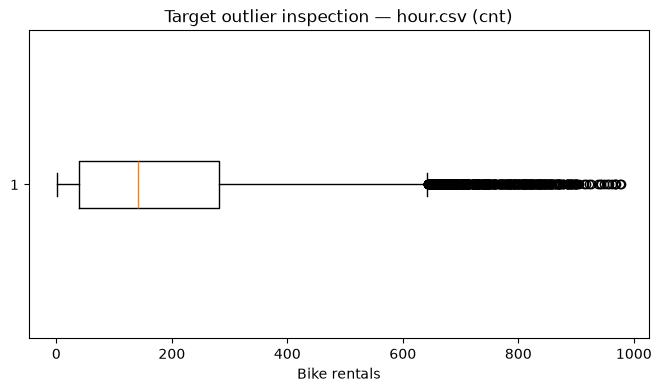

IQR inspection bounds: -321.50 to 642.50
Rows outside IQR bounds: 505 of 17,379
These are flagged for inspection, not automatically deleted.


In [8]:
plt.figure(figsize=(8, 4))
plt.boxplot(df["cnt"].dropna(), vert=False)
plt.title(f"Target outlier inspection — {DATASET_TO_TRAIN}.csv (cnt)")
plt.xlabel("Bike rentals")
plt.show()

q1, q3 = df["cnt"].quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
suspected = df[(df["cnt"] < lower_bound) | (df["cnt"] > upper_bound)]
print(f"IQR inspection bounds: {lower_bound:.2f} to {upper_bound:.2f}")
print(f"Rows outside IQR bounds: {len(suspected):,} of {len(df):,}")
print("These are flagged for inspection, not automatically deleted.")

## Step 7 — Define features and split chronologically

For hourly training, the features match the existing project:
- Numeric: `temp`, `atemp`, `hum`, `windspeed`
- Categorical: `season`, `yr`, `mnth`, `hr`, `holiday`, `weekday`, `workingday`, `weathersit`

For daily training, `hr` is not available, so the daily model uses the corresponding daily features. `cnt` is the target in both files, but the unit is different: rentals **per hour** versus rentals **per day**.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERIC = ["temp", "atemp", "hum", "windspeed"]
CATEGORICAL = ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]
if DATASET_TO_TRAIN == "hour":
    CATEGORICAL = CATEGORICAL + ["hr"]

FEATURES = NUMERIC + CATEGORICAL
TARGET = "cnt"

missing_features = set(FEATURES + [TARGET]) - set(df.columns)
if missing_features:
    raise ValueError(f"Missing required columns: {sorted(missing_features)}")

X = df[FEATURES].copy()
y = df[TARGET].astype(float).copy()

n = len(df)
train_end, val_end = int(n * 0.70), int(n * 0.85)
X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

print(f"Features: {FEATURES}")
print(f"Target: {TARGET}")
print(f"Train rows: {len(X_train):,} ({len(X_train)/n:.0%})")
print(f"Validation rows: {len(X_val):,} ({len(X_val)/n:.0%})")
print(f"Test rows: {len(X_test):,} ({len(X_test)/n:.0%})")

Features: ['temp', 'atemp', 'hum', 'windspeed', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'hr']
Target: cnt
Train rows: 12,165 (70%)
Validation rows: 2,607 (15%)
Test rows: 2,607 (15%)


## Step 8 — Train and compare five algorithms

- **Dummy Regressor:** baseline that predicts the training-set mean.
- **Linear Regression:** simple additive linear relationship.
- **Random Forest:** averages many decision trees.
- **Extra Trees:** uses more randomized tree splits.
- **Hist Gradient Boosting:** builds trees sequentially to improve earlier errors.

Preprocessing is fit only on training data inside each pipeline, helping avoid leakage. Validation RMSE chooses the winning model.

In [10]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def build_pipeline(model):
    preprocess = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), NUMERIC),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), CATEGORICAL),
    ])
    return Pipeline([("preprocess", preprocess), ("model", model)])

def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

models = {
    "Dummy baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=250, min_samples_leaf=2, random_state=42, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=250, min_samples_leaf=2, random_state=42, n_jobs=-1
    ),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=180, learning_rate=0.08, l2_regularization=1.0, random_state=42
    ),
}

results = []
fitted_models = {}

for name, estimator in models.items():
    pipe = build_pipeline(estimator)
    pipe.fit(X_train, y_train)
    val_pred = np.maximum(0, pipe.predict(X_val))
    row = {"Model": name, **calculate_metrics(y_val, val_pred)}
    results.append(row)
    fitted_models[name] = pipe

comparison = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(comparison.style.format({"MAE": "{:.3f}", "RMSE": "{:.3f}", "R2": "{:.4f}"}))
comparison.to_csv("model_comparison.csv", index=False)
best_name = comparison.iloc[0]["Model"]
print("Best model based on lowest validation RMSE:", best_name)

,Model,MAE,RMSE,R2
0,Hist Gradient Boosting,66.286,86.634,0.8494
1,Extra Trees,62.025,87.222,0.8473
2,Random Forest,98.336,139.398,0.6101
3,Linear Regression,110.541,141.520,0.5981
4,Dummy baseline,194.135,253.970,-0.2943


Best model based on lowest validation RMSE: Hist Gradient Boosting


## Step 9 — Refit the selected model and evaluate on the test set

After choosing by validation RMSE, train a fresh pipeline on train + validation. The final chronological 15% test set remains untouched until this final evaluation.

Selected model: Hist Gradient Boosting
Held-out test metrics:
  MAE: 50.0965
  RMSE: 72.9196
  R2: 0.8851


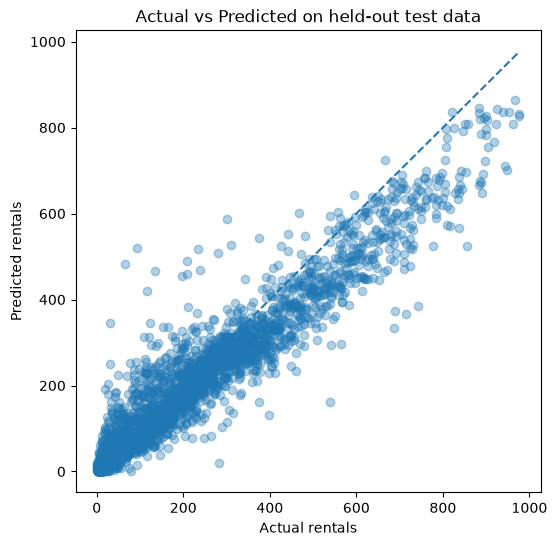

In [11]:
import json
import joblib

X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

final_model = build_pipeline(models[best_name])
final_model.fit(X_trainval, y_trainval)
test_pred = np.maximum(0, final_model.predict(X_test))
test_metrics = calculate_metrics(y_test, test_pred)

print("Selected model:", best_name)
print("Held-out test metrics:")
for metric_name, value in test_metrics.items():
    print(f"  {metric_name}: {value:.4f}")

plt.figure(figsize=(6, 6))
plt.scatter(y_test, test_pred, alpha=0.35)
lims = [min(y_test.min(), test_pred.min()), max(y_test.max(), test_pred.max())]
plt.plot(lims, lims, linestyle="--")
plt.xlabel("Actual rentals")
plt.ylabel("Predicted rentals")
plt.title("Actual vs Predicted on held-out test data")
plt.show()

predictions = pd.DataFrame({"actual": y_test.to_numpy(), "predicted": test_pred})
predictions.to_csv("test_predictions.csv", index=False)
with open("final_metrics.json", "w") as f:
    json.dump({"dataset": DATASET_TO_TRAIN, "selected_model": best_name,
               "test_metrics": {k: float(v) for k, v in test_metrics.items()}}, f, indent=2)

## Step 10 — Save the trained model as Joblib

For hourly training, the saved bundle uses the same key structure and feature order as the existing project (`pipeline`, `features`, `numeric_features`, `categorical_features`, `target`, `model_name`, `test_metrics`, `dataset`).

- `hour.csv` → `bike_demand_model.joblib`
- `day.csv` → `daily_bike_demand_model.joblib` (separate daily model, not a drop-in replacement for the hourly app)

Download the `.joblib` file and replace the existing model at `bike_project/models/bike_demand_model.joblib` only when you trained using **hour.csv**.

In [12]:
output_model = "bike_demand_model.joblib" if DATASET_TO_TRAIN == "hour" else "daily_bike_demand_model.joblib"

model_bundle = {
    "pipeline": final_model,
    "features": FEATURES,
    "numeric_features": NUMERIC,
    "categorical_features": CATEGORICAL,
    "target": TARGET,
    "model_name": best_name,
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    "dataset": f"UCI Bike Sharing Dataset ({DATASET_TO_TRAIN}.csv)",
}
joblib.dump(model_bundle, output_model)

print("Saved:", output_model)
print("Also saved: model_comparison.csv, final_metrics.json, test_predictions.csv")

Saved: bike_demand_model.joblib
Also saved: model_comparison.csv, final_metrics.json, test_predictions.csv


## Step 11 — Download the model and reports

Run this cell to download the model file to your computer. Upload the downloaded hourly model to your project repository or copy it into `models/` locally.

In [13]:
from google.colab import files
files.download(output_model)
files.download("model_comparison.csv")
files.download("final_metrics.json")
files.download("test_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## How to use the downloaded `.joblib` in the project

For **hour.csv** training only:
1. Download `bike_demand_model.joblib`.
2. In your local project, put it here: `bike_project/models/bike_demand_model.joblib` (replace the existing file only if you intend to use the new trained model).
3. Ensure the frontend/backend loads the model from that path.
4. Run the backend and Streamlit app as before.

```python
import joblib
bundle = joblib.load("models/bike_demand_model.joblib")
pipeline = bundle["pipeline"]
features = bundle["features"]
# A prediction input must contain all features in the same names/order.
prediction = pipeline.predict(input_dataframe[features])
```

**Outlier explanation for presentation:** We checked outliers using a box plot and IQR bounds, but did not delete them automatically because unusually high rental counts can be genuine peak demand. We removed invalid dates, missing target rows, duplicate records and negative target values. Missing feature values are handled inside the preprocessing pipeline using median (numeric) and most-frequent (categorical) imputation.

**Dataset difference for presentation:** `hour.csv` has hourly observations and includes `hr`; `day.csv` has daily observations and no `hr`. Both contain `cnt`, but hourly `cnt` is rentals in one hour while daily `cnt` is rentals for the whole day. The existing app uses hourly input features, so train it with `hour.csv`.